b = 0 Energy = 96.59387475780285
b = 10 Energy = 102.06796111353623
b = 20 Energy = 106.97258125332225


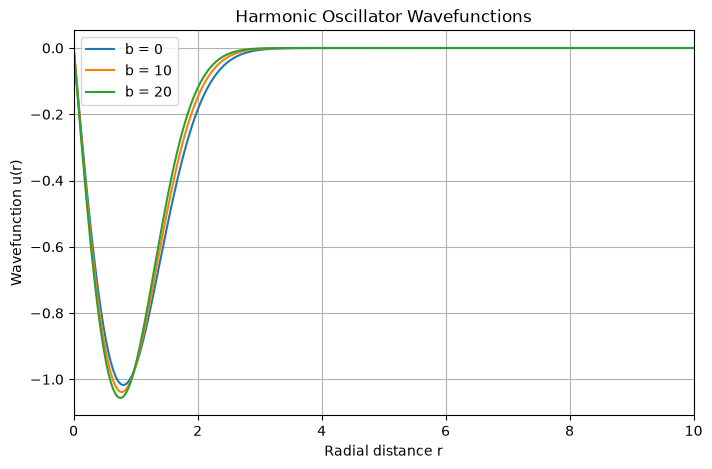

In [1]:

import numpy as np
import matplotlib.pyplot as plt


mc2 = 940
hbar_c = 197.3
k = 100

C = hbar_c**2 / (2 * mc2)


ri = 0.001
rf = 20
N = 500

dr = (rf - ri) / (N + 1)
r = ri + dr * np.arange(1, N + 1)


l = 0


b_list = [0, 10, 20]

plt.figure(figsize=(8, 5))

for b in b_list:

    
    V = (k * r**2) / 2 + (b * r**3) / 2

    
    V = V + C * l * (l + 1) / r**2

    
    main = 2 * C / dr**2 + V
    side = -C / dr**2

    H = np.diag(main)
    H += np.diag(np.full(N - 1, side), 1)
    H += np.diag(np.full(N - 1, side), -1)

    
    energy, wavefunction = np.linalg.eigh(H)

    
    u = wavefunction[:, 0]

    
    u = np.concatenate(([0], u, [0]))

    
    u = u / np.sqrt(np.sum(u**2) * dr)

    
    print("b =", b, "Energy =", energy[0])

    
    plt.plot(
        np.concatenate(([ri], r, [rf])),
        u,
        label="b = " + str(b)
    )

plt.xlabel("Radial distance r")
plt.ylabel("Wavefunction u(r)")
plt.title("Harmonic Oscillator Wavefunctions")
plt.xlim(0, 10)
plt.grid()
plt.legend()
plt.show()
